# 04casestudy: the episode chart for the case study

Draws `docs/images/cs_episode.png` from `docs/data/smog.json`: PM2.5 at the nine stations (top) and the lid (bottom), with the declared days and the nights shaded. Uses the case study font (Bricolage Grotesque), converted from the woff2 files in `docs/fonts`.

## 0. Settings

In [1]:
from pathlib import Path
import json
import math
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.font_manager import FontProperties
from fontTools.ttLib import TTFont

SMOG_JSON = Path("docs") / "data" / "smog.json"
FONT_DIR = Path("docs") / "fonts"
TTF_DIR = Path("data") / "fonts"
OUT_PNG = Path("docs") / "images" / "cs_episode.png"  # <- the case study figure
PRE_DAYS = ["2026-06-13", "2026-06-14", "2026-06-15", "2026-06-17"]  # <- preemergencia declared
ALE_DAYS = ["2026-06-16"]  # <- alerta declared
INK = "#1f2430"  # VISUAL: label colour
SOFT = "#5b6270"  # VISUAL: tick colour
WEST = "#2f3136"  # VISUAL: Cerro Navia line
EAST = "#8f949c"  # VISUAL: Las Condes line
OTHER = "#d3d6db"  # VISUAL: the other seven stations
LID = "#3d5a80"  # VISUAL: mixing layer
RESIDUAL = "#b9bdc4"  # VISUAL: residual layer
PRE = "#9a3412"  # VISUAL: preemergencia
ALE = "#d97706"  # VISUAL: alerta

## 1. Fonts for matplotlib

matplotlib cannot read woff2, so each weight is converted to a ttf once (needs fonttools and brotli).

In [2]:
TTF_DIR.mkdir(parents=True, exist_ok=True)
fonts = {}
for w in ["600", "700"]:
    ttf = TTF_DIR / f"bricolage-grotesque-latin-{w}-normal.ttf"
    if not ttf.exists():
        f = TTFont(FONT_DIR / f"bricolage-grotesque-latin-{w}-normal.woff2")
        f.flavor = None
        f.save(ttf)
    fonts[w] = FontProperties(fname=str(ttf))
FONT_600 = fonts["600"]
FONT_700 = fonts["700"]
print("Fonts ready:", sorted(p.name for p in TTF_DIR.glob("*.ttf")))

Fonts ready: ['bricolage-grotesque-latin-600-normal.ttf', 'bricolage-grotesque-latin-700-normal.ttf']


## 2. Read the episode

In [3]:
d = json.load(open(SMOG_JSON, encoding="utf-8"))
t = [datetime.fromisoformat(s[:16]) for s in d["times"]]
names = [s["name"] for s in d["stations"]]
cn = names.index("Cerro Navia")
lc = names.index("Las Condes")
print(len(t), "hours from", t[0], "to", t[-1])


def sun_elev(dt_local):
    dt = dt_local + timedelta(hours=4)
    n = dt.timetuple().tm_yday
    g = 2 * math.pi / 365 * (n - 1 + (dt.hour - 12) / 24)
    decl = 0.006918 - 0.399912 * math.cos(g) + 0.070257 * math.sin(g) - 0.006758 * math.cos(2 * g) + 0.000907 * math.sin(2 * g)
    eq = 229.18 * (0.000075 + 0.001868 * math.cos(g) - 0.032077 * math.sin(g) - 0.014615 * math.cos(2 * g) - 0.040849 * math.sin(2 * g))
    tst = dt.hour * 60 + dt.minute + eq + 4 * -70.65
    ha = math.radians(tst / 4 - 180)
    lat = math.radians(-33.45)
    return math.degrees(math.asin(math.sin(lat) * math.sin(decl) + math.cos(lat) * math.cos(decl) * math.cos(ha)))

215 hours from 2026-06-11 01:00:00 to 2026-06-19 23:00:00


## 3. Draw the chart

Saved docs/images/cs_episode.png


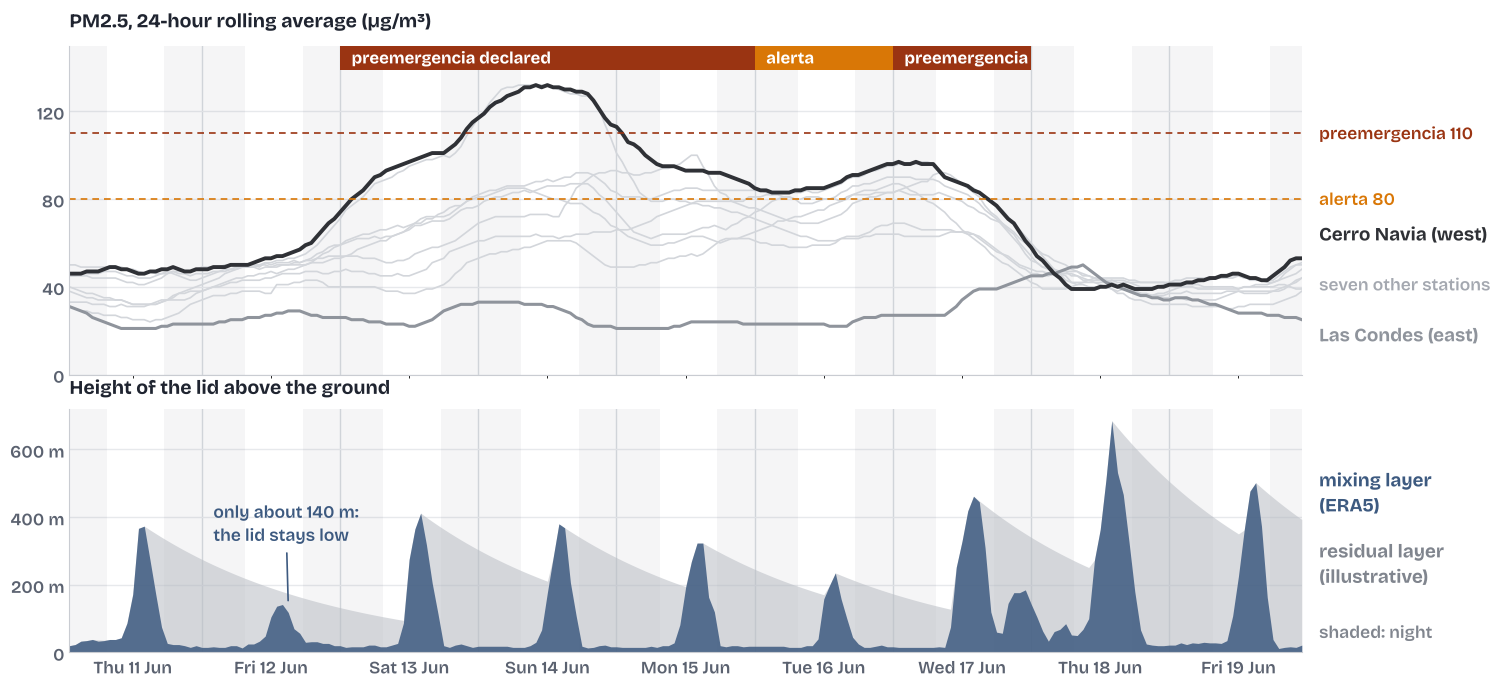

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15.6, 7.4), dpi=100, sharex=True, gridspec_kw={"height_ratios": [1.35, 1], "hspace": 0.12})
fig.subplots_adjust(left=0.07, right=0.86, top=0.9, bottom=0.08)

# night shading (sun below the horizon), axes styling
for ax in (ax1, ax2):
    for i, ti in enumerate(t):
        if sun_elev(ti) < 0:
            ax.axvspan(ti - timedelta(minutes=30), ti + timedelta(minutes=30), color="#1b2433", alpha=0.045, lw=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#c9ccd2")
    ax.spines["bottom"].set_color("#c9ccd2")
    ax.tick_params(colors=SOFT, length=0)
    for lab in ax.get_yticklabels() + ax.get_xticklabels():
        lab.set_fontproperties(FONT_600)
        lab.set_fontsize(12.5)

# declared days as a band along the top
for day in PRE_DAYS + ALE_DAYS:
    d0 = datetime.fromisoformat(day)
    ax1.axvspan(d0, d0 + timedelta(days=1), ymin=0.925, ymax=1.0, color=PRE if day in PRE_DAYS else ALE, lw=0)
ax1.text(datetime(2026, 6, 13, 2), 144.4, "preemergencia declared", color="white", fontproperties=FONT_700, fontsize=12, va="center")
ax1.text(datetime(2026, 6, 16, 2), 144.4, "alerta", color="white", fontproperties=FONT_700, fontsize=12, va="center")
ax1.text(datetime(2026, 6, 17, 2), 144.4, "preemergencia", color="white", fontproperties=FONT_700, fontsize=12, va="center")

# PM2.5
for k in range(len(names)):
    if k in (cn, lc):
        continue
    ax1.plot(t, [r[k] for r in d["pm25"]], color=OTHER, lw=1.2)
ax1.plot(t, [r[lc] for r in d["pm25"]], color=EAST, lw=2.2)
ax1.plot(t, [r[cn] for r in d["pm25"]], color=WEST, lw=2.8)
for v, name, col in [(80, "alerta 80", ALE), (110, "preemergencia 110", PRE)]:
    ax1.axhline(v, color=col, lw=1.2, ls=(0, (4, 3)))
    ax1.text(t[-1] + timedelta(hours=3), v, name, color=col, fontproperties=FONT_600, fontsize=12.5, va="center")
last = len(t) - 1
ax1.text(t[-1] + timedelta(hours=3), 64, "Cerro Navia (west)", color=WEST, fontproperties=FONT_700, fontsize=13.5, va="center")
ax1.text(t[-1] + timedelta(hours=3), 18, "Las Condes (east)", color=EAST, fontproperties=FONT_700, fontsize=13.5, va="center")
ax1.text(t[-1] + timedelta(hours=3), 41, "seven other stations", color="#a4a8b0", fontproperties=FONT_600, fontsize=12.5, va="center")
ax1.set_ylim(0, 150)
ax1.set_yticks([0, 40, 80, 120])
ax1.grid(axis="y", color="#e7e9ec", lw=1)
ax1.set_axisbelow(True)
ax1.text(0, 1.04, "PM2.5, 24-hour rolling average (µg/m³)", transform=ax1.transAxes, color=INK, fontproperties=FONT_700, fontsize=14, va="bottom")

# lid
ax2.fill_between(t, d["residual"], color=RESIDUAL, alpha=0.55, lw=0)
ax2.fill_between(t, d["blh"], color=LID, alpha=0.85, lw=0)
ax2.set_ylim(0, 720)
ax2.set_yticks([0, 200, 400, 600])
ax2.set_yticklabels(["0", "200 m", "400 m", "600 m"])
ax2.grid(axis="y", color="#e7e9ec", lw=1)
ax2.set_axisbelow(True)
ax2.text(0, 1.04, "Height of the lid above the ground", transform=ax2.transAxes, color=INK, fontproperties=FONT_700, fontsize=14, va="bottom")
ax2.text(t[-1] + timedelta(hours=3), 470, "mixing layer\n(ERA5)", color=LID, fontproperties=FONT_700, fontsize=13.5, va="center", linespacing=1.1)
ax2.text(t[-1] + timedelta(hours=3), 260, "residual layer\n(illustrative)", color="#80858e", fontproperties=FONT_700, fontsize=13.5, va="center", linespacing=1.1)
ax2.text(t[-1] + timedelta(hours=3), 60, "shaded: night", color="#80858e", fontproperties=FONT_600, fontsize=12.5, va="center")

ax2.annotate("only about 140 m:\nthe lid stays low", xy=(datetime(2026, 6, 12, 15), 145), xytext=(datetime(2026, 6, 12, 2), 330), color=LID, fontproperties=FONT_600, fontsize=12.5, ha="left", linespacing=1.1, arrowprops=dict(arrowstyle="-", color=LID, lw=1.2))
ax2.set_xlim(t[0], t[-1])
ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: ""))
ax2.xaxis.set_minor_locator(mdates.HourLocator(byhour=12))
ax2.xaxis.set_minor_formatter(mdates.DateFormatter("%a %d Jun"))
ax2.tick_params(axis="x", which="minor", length=0, colors=SOFT)
for lab in ax2.get_xticklabels(minor=True):
    lab.set_fontproperties(FONT_600)
    lab.set_fontsize(12.5)
for ax in (ax1, ax2):
    ax.grid(axis="x", which="major", color="#d9dce1", lw=1)

OUT_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_PNG, dpi=100, facecolor="white")
print("Saved", OUT_PNG)
plt.show()

___
**END**